# 📦 Package Delivery Prediction with a Simple Neural Network

## Problem Description

In this project, I build a simple neural network to predict whether a package can be delivered the following day.
The goal is to understand the fundamentals of neural networks by implementing one from scratch.

## Dataset

For this first experiment, I use a simple synthetic dataset with three features:

**Features (input):**
- Distance (km) to the destination
- Shipping time (e.g., "morning" vs. "afternoon")
- Weather condition at the destination (e.g., clear vs. storm/snow)

**Target (prediction):**
- Delivery possible the following day? (1 = Yes / 0 = No)

## Objective

The objective is to implement a neural network with one hidden layer from scratch, including:
- model prediction (forward propagation)
- cost function
- gradient descent optimization
- feature scaling

After training, the model should be able to predict whether next-day delivery is possible and output a clear binary classification (Yes/No) based on a 0.5 threshold, visualized with a decision boundary.

In [905]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


## 1. Sigmoid Function
The sigmoid function maps any real-valued number into a probability between 0 and 1:
$$g(z) = \frac{1}{1 + e^{-z}}$$

In [906]:
def sigmoid(z):
    
    """Compute the sigmoid of z."""
    
    return 1 / (1 + np.exp(-z))

## 2. Generate Data

In [907]:
np.random.seed(42) # fixed seed for reproducible random data

number_of_samples = 500

# Feature 1: Distance to destination (km)
# for example: [12.3, 487.1, 250.8, 45.2, 399.9]
distance = np.random.uniform(1, 500, number_of_samples) # 1 – 500 km

# Feature 2: Shipping time, encoded as 0 = morning, 1 = afternoon
# for example: [0, 1, 1, 0, 0]
shipping_time = np.random.randint(0, 2, number_of_samples)

# Feature 3: Weather condition, encoded as 0 = clear, 1 = storm/snow
# for example: [1, 1, 0, 0, 1]
weather = np.random.randint(0, 2, number_of_samples) 

X = np.column_stack((distance, shipping_time, weather))

# Base probability of next-day delivery
# - shorter distance -> higher chance
# - morning shipping -> higher chance
# - bad weather -> lower chance

bias = 3.0  # base tendency toward on-time delivery (before considering features)

# w (weights) = weights for each Feature
# b (bias) = additional constant
# z = w1*x1 + w2*x2 + ... + b
z = (
    - 0.015 * distance
    + 1.5 * (shipping_time == 0)
    - 2.0 * weather
    - 0.01 * distance * weather # interaction: bad weather hurts more over long distances
    + bias
)
probability = sigmoid(z)

# Convert probability into a random binary outcome (Bernoulli sampling):
# draw a random number in [0, 1) and compare it to the probability —
# this adds natural randomness instead of a hard 0.5 threshold.
y = (np.random.uniform(0, 1, number_of_samples) < probability).astype(int)
next_day_delivery = np.where(y == 1, "Yes 📦", "No ❌")

print(f"Number of training examples: {number_of_samples}")
display(pd.DataFrame({
    "distance (km)": distance,
    "shipping time (0 = morning, 1 = afternoon)": shipping_time,
    "weather (0 = clear, 1 = storm/snow)": weather,
    "next_day_delivery": next_day_delivery
}).head())

Number of training examples: 500


,distance (km),"shipping time (0 = morning, 1 = afternoon)","weather (0 = clear, 1 = storm/snow)",next_day_delivery
0,187.895519,1,0,Yes 📦
1,475.406439,0,1,No ❌
2,366.264977,0,1,No ❌
3,299.730584,0,0,No ❌
4,78.853302,0,0,Yes 📦


## 3. Visualize Data

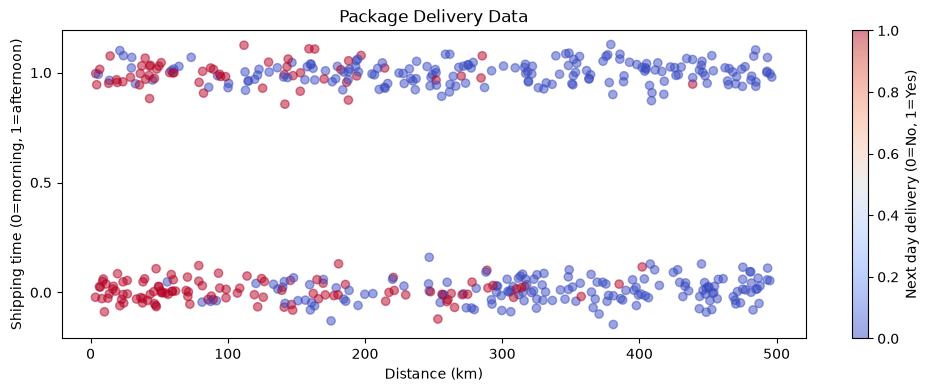

In [908]:
# Add small random jitter so overlapping points (0 or 1) become visible
# instead of stacking exactly on top of each other
jitter =  np.random.normal(0, 0.05, number_of_samples)

plt.figure(figsize=(12, 4))
plt.scatter(distance, shipping_time + jitter, c=y, cmap="coolwarm", alpha=0.5)
plt.xlabel("Distance (km)")
plt.ylabel("Shipping time (0=morning, 1=afternoon)")
plt.yticks([0, 0.5, 1])
plt.title("Package Delivery Data")
plt.colorbar(label="Next day delivery (0=No, 1=Yes)")
plt.show()

## 4. Feature Scaling (Z-score Normalization)

All features will have a mean of 0 and a standard deviation of 1 after z-score normalization.

$$
\begin{aligned} 
x^{(i)}_j = \dfrac{x^{(i)}_j - \mu_j}{\sigma_j}
\end{aligned} 
$$  

where $j$ selects a feature or a column in the $\mathbf{X}$ matrix. $\mu_j$ is the mean of all the values for feature (j) and $\sigma_j$ is the standard deviation of feature (j). 

$$ 
\begin{aligned} 
\mu_j &= \frac{1}{m} \sum_{i=0}^{m-1} x^{(i)}_j \\
\sigma^2_j &= \frac{1}{m} \sum_{i=0}^{m-1} (x^{(i)}_j - \mu_j)^2 \\
\sigma_j &= \sqrt{\sigma^2_j}
\end{aligned} 
$$


In [909]:
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_scaled = (X - X_mean) / X_std

print(f"X_mean: {X_mean}")
print(f"X_std: {X_std}")
print(f"X_scaled[:5]:\n{X_scaled[:5]}")

X_mean: [249.7822944   0.474       0.474    ]
X_std: [148.89639568   0.49932354   0.49932354]
X_scaled[:5]:
[[-0.41563649  1.05342519 -0.9492843 ]
 [ 1.51530965 -0.9492843   1.05342519]
 [ 0.78230693 -0.9492843   1.05342519]
 [ 0.33545667 -0.9492843  -0.9492843 ]
 [-1.14797267 -0.9492843  -0.9492843 ]]


## 5. Build the Neural Network

The network has three input features, one hidden layer with 6 neurons and a single output neuron.

```mermaid
%%{init: {'flowchart': {'nodeSpacing': 10, 'rankSpacing': 80}}}%%
graph LR
    subgraph Input["Input Layer"]
        X1[Distance]
        X2[Shipping Time]
        X3[Weather]
        
    end

    subgraph Hidden["Hidden Layer (W1, b1)"]
        H1((h1))
        H2((h2))
        H3((h3))
        H4((h4))
        H5((h5))
        H6((h6))
    end

    subgraph Output["Output Layer (W2, b2)"]
        O1((Next-day<br/>delivery))
    end

    X1 --> H1
    X1 --> H2
    X1 --> H3
    X1 --> H4
    X1 --> H5
    X1 --> H6

    X2 --> H1
    X2 --> H2
    X2 --> H3
    X2 --> H4
    X2 --> H5
    X2 --> H6

    X3 --> H1
    X3 --> H2
    X3 --> H3
    X3 --> H4
    X3 --> H5
    X3 --> H6

    H1 --> O1
    H2 --> O1
    H3 --> O1
    H4 --> O1
    H5 --> O1
    H6 --> O1
```

## 6. Forward Propagation

Forward propagation computes the network's prediction by passing the input through each layer in sequence: first the hidden layer, then the output layer. Each layer computes a weighted sum of its inputs (`Z`), then applies the sigmoid activation function to produce the layer's output (`A`).

$$Z_1 = X \cdot W_1 + b_1 \qquad A_1 = g(Z_1)$$

$$Z_2 = A_1 \cdot W_2 + b_2 \qquad A_2 = g(Z_2)$$

`A1` is the hidden layer's activation, and `A2` is the network's final prediction — the probability that next-day delivery is possible.

In [910]:
def forward_propagation(X, W1, b1, W2, b2):

    """Computes forward propagation.

    Args:
        X: input feature values
        W1: weight matrix for hidden layer
        b1: bias vector for hidden layer
        W2: weight matrix for output layer
        b2: bias vector for output layer

    Returns:
        A2: sigmoid activation of the output layer (final prediction)
        A1: sigmoid activation of the hidden layer
    """

    # Hidden layer with 6 neurons
    Z1 = np.dot(X, W1) + b1 # pre-activation (linear) values of the hidden layer
    A1 = sigmoid(Z1)

    # Output layer with 1 neuron
    Z2 = np.dot(A1, W2) + b2 # pre-activation (linear) value of the output layer
    A2 = sigmoid(Z2) 

    return A2, A1

## 7. Initialize Parameters

In [911]:
np.random.seed(1)  # for reproducible parameter initialization

n_input = 3    # number of features (distance, shipping time, weather)
n_hidden = 6   # number of neurons in the hidden layer
n_output = 1   # number of neurons in the output layer (binary classification)

# Small random weights (common practice to break symmetry between neurons)
W1 = np.random.randn(n_input, n_hidden) * 0.01
b1 = np.zeros(n_hidden)

W2 = np.random.randn(n_hidden, n_output) * 0.01
b2 = np.zeros(n_output)

print(f"W1 shape: {W1.shape}")
print(f"b1 shape: {b1.shape}")
print(f"W2 shape: {W2.shape}")
print(f"b2 shape: {b2.shape}")

W1 shape: (3, 6)
b1 shape: (6,)
W2 shape: (6, 1)
b2 shape: (1,)


## 8. Cost Function (Log Loss / Logistic Loss)
For binary classification, we use the binary cross-entropy loss function, applied to the network's final prediction:

$$J = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log(A_2^{(i)}) + (1 - y^{(i)}) \log(1 - A_2^{(i)}) \right]$$

In [912]:
def compute_cost(A2, y):

    """Compute the binary cross-entropy cost for the network's predictions.

    Args:
        A2: result of the forward propagation
        y: target values

    Returns:
        total_cost: the computed cost J
    """
    
    m = A2.shape[0] # number of training examples
    y_reshaped = y.reshape(-1, 1) # same matrix format as A2

    cost = -(y_reshaped * np.log(A2) + (1 - y_reshaped) * np.log(1 - A2))
    total_cost = np.sum(cost) / m

    return total_cost

## 9. Backward Propagation

Backward propagation computes how much each parameter (`W1`, `b1`, `W2`, `b2`) contributed to the error, so we know how to adjust them (this is what gradient descent will use in the next step).

We start at the output layer and work backwards toward the input layer, applying the chain rule at each step.

**Step 1: Error at the output layer**

For a sigmoid output combined with binary cross-entropy loss, the derivative simplifies to:

$$dZ_2 = A_2 - Y$$

**Step 2: Gradients for the output layer weights and bias**

$$dW_2 = \frac{1}{m} A_1^T \cdot dZ_2$$

$$db_2 = \frac{1}{m} \sum_{i=1}^{m} dZ_2^{(i)}$$

**Step 3: Error propagated back to the hidden layer**

$$dZ_1 = (dZ_2 \cdot W_2^T) * A_1 * (1 - A_1)$$

The term $A_1 * (1 - A_1)$ is the derivative of the sigmoid function, needed here because the hidden layer was also activated with sigmoid.

**Step 4: Gradients for the hidden layer weights and bias**

$$dW_1 = \frac{1}{m} X^T \cdot dZ_1$$

$$db_1 = \frac{1}{m} \sum_{i=1}^{m} dZ_1^{(i)}$$

In [913]:
def backward_propagation(X, y, A1, A2, W2):

    """Computes backward propagation to calculate gradients.

    Args:
        X: input feature values
        y: target values
        A1: sigmoid activation of the hidden layer (from forward propagation)
        A2: sigmoid activation of the output layer (from forward propagation)
        W2: weight matrix for the output layer (needed to propagate the error back to the hidden layer)

    Returns:
        dW1: gradient of the cost with respect to W1
        db1: gradient of the cost with respect to b1
        dW2: gradient of the cost with respect to W2
        db2: gradient of the cost with respect to b2
    """

    m = A1.shape[0] # number of training examples
    y_reshaped = y.reshape(-1, 1) # same matrix format as A2

    # Error at the output layer
    dZ2 = A2 - y_reshaped

    # Gradients for the output layer weights and bias
    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0) / m

    # Error propagated back to the hidden layer
    dZ1 = np.dot(dZ2, W2.T) * A1 * (1 - A1)

    # Gradients for the hidden layer weights and bias
    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0) / m

    return dW1, db1, dW2, db2

## 10. Gradient Descent

In [914]:
def gradient_descent(X, y, W1, b1, W2, b2, alpha, number_of_iterations):
    """Perform gradient descent to train the neural network.

    Args:
        X: input feature values
        y: target values
        W1, b1, W2, b2: initial parameters
        alpha: learning rate
        number_of_iterations: number of gradient descent steps to run

    Returns:
        W1, b1, W2, b2: learned parameters
        J_history: list of cost values at each iteration
    """

    J_history = []

    for i in range(number_of_iterations):

        # Forward propagation
        A2, A1 = forward_propagation(X, W1, b1, W2, b2)

        # Backward propagation
        dW1, db1, dW2, db2 = backward_propagation(X, y, A1, A2, W2)

        # Update parameters
        W1 = W1 - alpha * dW1
        b1 = b1 - alpha * db1
        W2 = W2 - alpha * dW2
        b2 = b2 - alpha * db2

        # Save data at each iteration to print gradient descent process
        if i < 100000: # prevent resource exhaustion, not more than 100000 iterations
            J_history.append(compute_cost(A2, y))

        if i % math.ceil(number_of_iterations / 10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:,.4f}")

    return W1, b1, W2, b2, J_history

## 11. Run Gradient Descent

In [915]:
# initialize parameters
np.random.seed(1)

W1_init = np.random.randn(n_input, n_hidden) * 0.01
b1_init = np.zeros(n_hidden)

W2_init = np.random.randn(n_hidden, n_output) * 0.01
b2_init = np.zeros(n_output)

# gradient descent settings
iterations = 1000
alpha = 0.5

# run gradient descent
W1_final, b1_final, W2_final, b2_final, J_hist = gradient_descent(
    X_scaled, 
    y, 
    W1_init, 
    b1_init, 
    W2_init, 
    b2_init, 
    alpha, 
    iterations
)

Iteration    0: Cost 0.6949
Iteration  100: Cost 0.4103
Iteration  200: Cost 0.2783
Iteration  300: Cost 0.2600
Iteration  400: Cost 0.2554
Iteration  500: Cost 0.2538
Iteration  600: Cost 0.2530
Iteration  700: Cost 0.2524
Iteration  800: Cost 0.2520
Iteration  900: Cost 0.2517


## 12. Evaluate the Model

The cost drops quickly in the first iterations and then flattens out. As a sanity check, the training accuracy is compared with a baseline that always guesses the majority class.

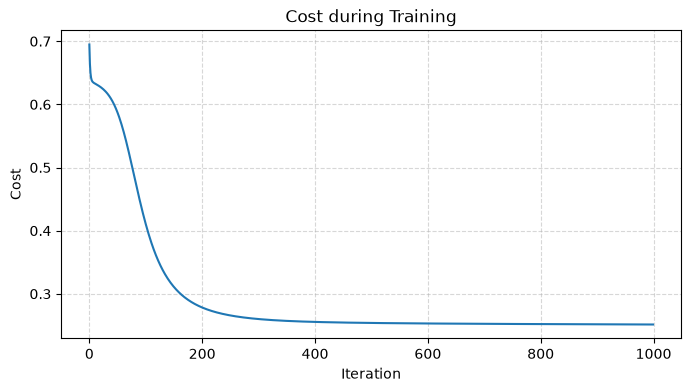

Training accuracy: 89.00%
Baseline (always guess the majority class): 66.80%


In [916]:
plt.figure(figsize=(8, 4))
plt.plot(J_hist)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost during Training")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

A2_final, _ = forward_propagation(X_scaled, W1_final, b1_final, W2_final, b2_final)
predictions = (A2_final >= 0.5).astype(int).flatten()
accuracy = np.mean(predictions == y)
print(f"Training accuracy: {accuracy:.2%}")

baseline = max(y.mean(), 1 - y.mean())
print(f"Baseline (always guess the majority class): {baseline:.2%}")

## 13. Make a Prediction

New packages must be scaled with the mean and standard deviation of the training data (`X_mean`, `X_std`). The column "True formula" is only shown for comparison, a real model would not know it.

In [917]:
def predict_package(distance_km, shipping_time, weather_condition):
    """Return the predicted probability of next-day delivery.

    Args:
        distance_km: distance to the destination in km
        shipping_time: 0 = morning, 1 = afternoon
        weather_condition: 0 = clear, 1 = storm/snow
    """
    
    data = np.array([distance_km, shipping_time, weather_condition])
    scaled = ((data - X_mean) / X_std).reshape(1, -1)

    A2_final, _ = forward_propagation(scaled, W1_final, b1_final, W2_final, b2_final)
    return A2_final[0, 0]

In [918]:
# (distance in km, shipping time, weather)
test_cases = [
    (50, 0, 0), 
    (50, 0, 1), 
    (450, 1, 1), 
    (300, 0, 0), 
    (200, 1, 0)
    ]

rows = []
for d, s, w in test_cases:
    prob = predict_package(d, s, w)

    # probability according to the formula used to generate the data
    z_true = (3.0 - 0.015 * d + 1.5 * (s == 0)
              - 2.0 * w - 0.01 * d * w)

    rows.append({
        "Distance": f"{d} km",
        "Shipping": "morning" if s == 0 else "afternoon",
        "Weather": "clear" if w == 0 else "storm/snow",
        "Network": f"{prob:.1%}",
        "True formula": f"{sigmoid(z_true):.1%}",
        "Next-day delivery": "Yes 📦" if prob >= 0.5 else "No ❌",
    })

display(pd.DataFrame(rows).style.hide(axis="index"))

Distance,Shipping,Weather,Network,True formula,Next-day delivery
50 km,morning,clear,96.4%,97.7%,Yes 📦
50 km,morning,storm/snow,79.2%,77.7%,Yes 📦
450 km,afternoon,storm/snow,0.2%,0.0%,No ❌
300 km,morning,clear,41.9%,50.0%,No ❌
200 km,afternoon,clear,51.1%,50.0%,Yes 📦


## 14. Decision Boundary

With three features, a single 2D plot cannot show the boundary like in the umbrella project. Instead, I plot the predicted probability over the distance for each combination of shipping time and weather. Where a curve crosses the 0.5 threshold, the prediction changes from "Yes" to "No".

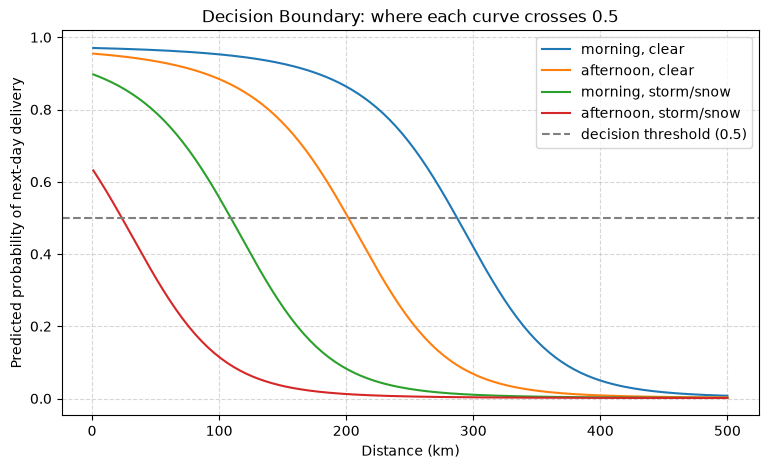

In [919]:
distances = np.linspace(1, 500, 200)
probs_morning_clear = [predict_package(d, 0, 0) for d in distances]
probs_afternoon_clear = [predict_package(d, 1, 0) for d in distances]
probs_morning_stormy = [predict_package(d, 0, 1) for d in distances]
probs_afternoon_stormy = [predict_package(d, 1, 1) for d in distances]

plt.figure(figsize=(9, 5))
plt.plot(distances, probs_morning_clear, label="morning, clear")
plt.plot(distances, probs_afternoon_clear, label="afternoon, clear")
plt.plot(distances, probs_morning_stormy, label="morning, storm/snow")
plt.plot(distances, probs_afternoon_stormy, label="afternoon, storm/snow")
plt.axhline(0.5, color="gray", linestyle="--", label="decision threshold (0.5)")
plt.xlabel("Distance (km)")
plt.ylabel("Predicted probability of next-day delivery")
plt.title("Decision Boundary: where each curve crosses 0.5")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 15. Reflection

The network reaches a training accuracy of 89%, compared to 66.8% for always guessing the majority class. There is no test split yet, so this number only describes the training data.

Building a neural network from scratch was hard. I am looking forward to working with TensorFlow next, and I want to come back to this notebook after some more practice.

In the next notebook, I plan to go through the full ML cycle: use an existing dataset, split it into training, validation and test sets, and compare more than one neural network architecture.